# 04 Season drift

In `03_hierarchical_pymc` the model predicted a wicket rate of 4.85% for the test seasons
(2024 and 2025) against an observed 5.04%. Neither model has a season term, and the raw
wicket rate has risen since 2020. This notebook asks whether adding one helps.

Two ways to add it:

* **Linear trend.** $\text{logit}\, p \mathrel{+}= \beta\,(\text{season} - 2016)/10$.
* **Random-walk level.** A level per season, $\ell_{2008} = 0$,
  $\ell_s = \ell_{s-1} + \sigma_{rw} z_s$, $z_s \sim N(0, 1)$. A future season gets the
  last level plus one random-walk step per season ahead.

The choice between "no term", "linear" and "random walk" is made on 2023 as a validation
season (fit on 2008 to 2022), never on the test seasons. The test seasons are scored once,
at the end, for the record.

In [1]:
import json
from pathlib import Path

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from scipy.special import expit, logit
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

from cricket_ba import hierarchical as H
from cricket_ba.evaluate import difference_interval, match_bootstrap, scores

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG, RESULTS = ROOT / "figures", ROOT / "results"
SEED = 20261112
FIRST = 2008

balls = pd.read_parquet(ROOT / "data" / "legal_balls.parquet")
base = pd.read_parquet(ROOT / "data" / "test_preds_baseline.parquet")
settings = json.load(open(RESULTS / "baseline_settings.json"))
TEST_SEASONS = settings["test_seasons"]
FEATS, C = settings["features"], settings["C"]
print("baseline features:", FEATS, "C =", C)

baseline features: ['batter_id', 'bowler_id', 'phase'] C = 0.03


## The raw rate by season

,mean,size,se
season,,,
2008,0.04656,12950,0.00185
2009,0.04731,13085,0.00186
2010,0.04473,13929,0.00175
2011,0.04481,16425,0.00161
2012,0.04480,17208,0.00158
2013,0.04701,17613,0.00159
2014,0.04366,13833,0.00174
2015,0.04741,13141,0.00185
2016,0.04318,13618,0.00174


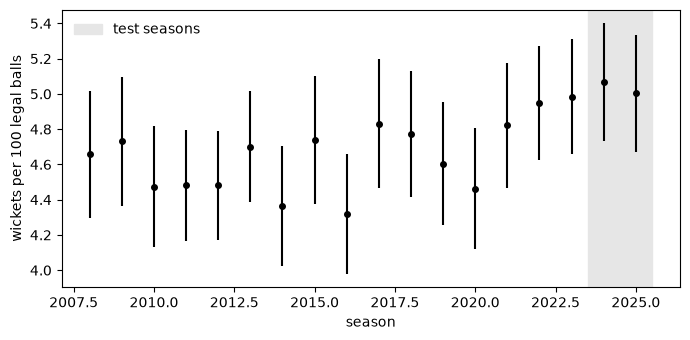

In [2]:
rate = balls.groupby("season")["wicket"].agg(["mean", "size"])
se = np.sqrt(rate["mean"] * (1 - rate["mean"]) / rate["size"])
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.errorbar(rate.index, 100 * rate["mean"], yerr=196 * se, fmt="o", color="k", ms=4)
ax.axvspan(TEST_SEASONS[0] - 0.5, TEST_SEASONS[-1] + 0.5, color="0.9", label="test seasons")
ax.set_xlabel("season")
ax.set_ylabel("wickets per 100 legal balls")
ax.legend(frameon=False)
fig.tight_layout()
rate.assign(se=se).round(5)

## Logistic baseline: does a season feature help?

Same expanding-window cross-validation as `02_baseline` (validate on each of 2019 to 2023,
fitting on every earlier season), at the chosen C, with and without a numeric season
column. Season is counted in years since 2008, so its coefficient is small and the L2
penalty barely touches it.

In [3]:
def logistic(feats, C, with_season):
    parts = [("onehot", OneHotEncoder(handle_unknown="ignore"), feats)]
    if with_season:
        parts.append(("season", "passthrough", ["years"]))
    enc = ColumnTransformer(parts, sparse_threshold=1.0)
    return make_pipeline(enc, LogisticRegression(C=C, max_iter=2000))


balls["years"] = balls["season"] - FIRST
train = balls[~balls.season.isin(TEST_SEASONS)].reset_index(drop=True)
test = balls[balls.season.isin(TEST_SEASONS)].reset_index(drop=True)
assert (test.wicket.to_numpy() == base.wicket.to_numpy()).all(), "test balls must match 02"

rows = []
for s in range(2019, 2024):
    tr, va = train[train.season < s], train[train.season == s]
    for with_season in [False, True]:
        cols = FEATS + (["years"] if with_season else [])
        m = logistic(FEATS, C, with_season).fit(tr[cols], tr.wicket)
        p = m.predict_proba(va[cols])[:, 1]
        rows.append({"season term": with_season, "val season": s, **scores(va.wicket, p),
                     "mean predicted": p.mean(), "observed": va.wicket.mean(),
                     "season coef": m[-1].coef_[0][-1] if with_season else np.nan})
lcv = pd.DataFrame(rows)
lcv.to_csv(RESULTS / "season_logistic_cv.csv", index=False)
display(lcv.round(5))
lcv.groupby("season term")[["log_loss", "brier"]].mean().round(6)

,season term,val season,log_loss,brier,mean predicted,observed,season coef
0,False,2019,0.18269,0.04351,0.04709,0.04604,NaN
1,True,2019,0.18268,0.04352,0.04611,0.04604,-0.00541
2,False,2020,0.17967,0.04238,0.04733,0.04462,NaN
3,True,2020,0.17962,0.04238,0.04666,0.04462,-0.00311
4,False,2021,0.18990,0.04555,0.04696,0.04821,NaN
5,True,2021,0.18995,0.04556,0.04600,0.04821,-0.00586
6,False,2022,0.19470,0.04679,0.04770,0.04948,NaN
7,True,2022,0.19474,0.04679,0.04710,0.04948,-0.00298
8,False,2023,0.19583,0.04713,0.04868,0.04983,NaN
9,True,2023,0.19585,0.04713,0.04871,0.04983,-0.00054


,log_loss,brier
season term,,
False,0.188557,0.045072
True,0.188568,0.045074


## Hierarchical model with a season term

The model of `03`, with cells now split by season as well, and one of three season terms.

In [4]:
def season_cells(df, idx):
    cells = df.groupby(H.KEYS + ["season"], observed=True)["wicket"].agg(n="size", k="sum")
    cells = cells.reset_index()
    cells["bat_idx"] = idx.batters.get_indexer(cells.batter_id)
    cells["bowl_idx"] = idx.bowlers.get_indexer(cells.bowler_id)
    cells["phase_idx"] = idx.phases.get_indexer(cells.phase)
    cells["s_idx"] = cells.season - FIRST
    return cells


def build(cells, idx, seasons, trend):
    coords = {"phase": list(idx.phases), "batter": list(idx.batters),
              "bowler": list(idx.bowlers), "season": seasons, "step": seasons[1:]}
    with pm.Model(coords=coords) as model:
        alpha = pm.Normal("alpha", mu=logit(0.05), sigma=0.5, dims="phase")
        sigma_bat = pm.HalfNormal("sigma_bat", 0.5)
        sigma_bowl = pm.HalfNormal("sigma_bowl", 0.5)
        bat = pm.Deterministic("bat", sigma_bat * pm.Normal("z_bat", 0, 1, dims="batter"),
                               dims="batter")
        bowl = pm.Deterministic("bowl", sigma_bowl * pm.Normal("z_bowl", 0, 1, dims="bowler"),
                                dims="bowler")
        eta = (alpha[cells.phase_idx.to_numpy()] + bat[cells.bat_idx.to_numpy()]
               + bowl[cells.bowl_idx.to_numpy()])
        if trend == "linear":
            beta = pm.Normal("beta", 0, 0.5)
            level = pm.Deterministic("level", beta * (seasons - 2016) / 10, dims="season")
        elif trend == "random walk":
            sigma_rw = pm.HalfNormal("sigma_rw", 0.1)
            z_rw = pm.Normal("z_rw", 0, 1, dims="step")
            level = pm.Deterministic(
                "level", pt.concatenate([pt.zeros(1), pt.cumsum(sigma_rw * z_rw)]), dims="season")
        if trend != "none":
            eta = eta + level[cells.s_idx.to_numpy()]
        pm.Binomial("k", n=cells.n.to_numpy(), logit_p=eta, observed=cells.k.to_numpy())
    return model


def season_shift(idata, trend, season, seed):
    """Logit shift for a future season, one value per posterior draw."""
    post = idata.posterior.stack(s=("chain", "draw"))
    S = post.sizes["s"]
    if trend == "none":
        return np.zeros(S)
    if trend == "linear":
        return post["beta"].to_numpy() * (season - 2016) / 10
    last = post["level"].isel(season=-1).to_numpy()
    ahead = season - int(post["season"][-1])
    z = np.random.default_rng(seed).standard_normal(S)
    return last + np.sqrt(ahead) * post["sigma_rw"].to_numpy() * z


def predict(df, idx, idata, trend, seed):
    """Posterior-mean wicket probability per ball of ``df``."""
    draws = H.Draws.from_idata(idata)
    out = np.empty(len(df))
    for s in sorted(df.season.unique()):
        rows = (df.season == s).to_numpy()
        cells = H.aggregate(df[rows])
        P = H.predict_draws(cells, idx, draws, seed)
        P = expit(logit(P) + season_shift(idata, trend, s, seed)[None, :])
        cells["p"] = P.mean(1)
        out[rows] = df[rows].merge(cells[H.KEYS + ["p"]], on=H.KEYS, how="left")["p"].to_numpy()
    return out


def fit(train_df, trend, seed):
    idx = H.make_index(train_df)
    seasons = np.arange(FIRST, train_df.season.max() + 1)
    with build(season_cells(train_df, idx), idx, seasons, trend):
        idata = pm.sample(**{**H.SAMPLER, "target_accept": 0.95}, random_seed=seed,
                          progressbar=False)
    return idx, idata


def diagnostics(idata, trend):
    names = ["alpha", "sigma_bat", "sigma_bowl", "z_bat", "z_bowl"]
    names += {"none": [], "linear": ["beta"], "random walk": ["sigma_rw", "z_rw"]}[trend]
    s = az.summary(idata, var_names=names, round_to=None)
    return {"divergences": int(idata.sample_stats["diverging"].sum()),
            "max rhat": round(float(s.r_hat.max()), 3), "min ess bulk": int(s.ess_bulk.min())}

## Choose on 2023

Fit each variant on 2008 to 2022 and score 2023. Sampler settings as in `03`, except
`target_accept = 0.95`, because $\sigma_{rw}$ sits close to zero and gives the random walk a
funnel.

In [5]:
TRENDS = ["none", "linear", "random walk"]
VAL = 2023
tr22, va23 = train[train.season < VAL], train[train.season == VAL].reset_index(drop=True)
val_rows, val_fits = [], {}
for trend in TRENDS:
    idx, idata = fit(tr22, trend, SEED)
    val_fits[trend] = idata
    p = predict(va23, idx, idata, trend, SEED)
    va23[f"p_{trend}"] = p
    val_rows.append({"season term": trend, **diagnostics(idata, trend),
                     **scores(va23.wicket, p), "mean predicted": p.mean()})
val = pd.DataFrame(val_rows)
val["observed"] = va23.wicket.mean()
val.to_csv(RESULTS / "season_validation_2023.csv", index=False)
val.round(6)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, sigma_bat, sigma_bowl, z_bat, z_bowl]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 209 seconds.


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


... (4 outputs left out)

NUTS: [alpha, sigma_bat, sigma_bowl, z_bat, z_bowl, sigma_rw, z_rw]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 270 seconds.


There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


,season term,divergences,max rhat,min ess bulk,log_loss,brier,mean predicted,observed
0,none,0,1.01,954,0.195743,0.047123,0.048864,0.049834
1,linear,0,1.01,1150,0.195723,0.047123,0.049709,0.049834
2,random walk,1,1.01,732,0.195722,0.047122,0.049278,0.049834


In [6]:
print(az.summary(val_fits["linear"], var_names=["beta"]).to_string())
print(az.summary(val_fits["random walk"], var_names=["sigma_rw"]).to_string())
vb = match_bootstrap(va23, [f"p_{t}" for t in TRENDS], n_boot=1000, seed=SEED)
pd.concat({t: difference_interval(vb, f"p_{t}", "p_none") for t in TRENDS[1:]})

       mean    sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  r_hat
beta  0.029  0.03  -0.026    0.086        0.0      0.0    5139.0    3374.0    1.0
           mean    sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  r_hat
sigma_rw  0.012  0.01     0.0    0.029        0.0      0.0    1459.0    1831.0   1.01


2.5%        median     97.5%
linear      log_loss -0.000069 -2.141403e-05  0.000027
            brier    -0.000005 -8.892081e-08  0.000005
random walk log_loss -0.000045 -2.140540e-05  0.000005
            brier    -0.000004 -9.799648e-07  0.000002

## Where did the rise go?

If player effects already explain the rise, then the model with *no* season term should
reproduce the rising rate in the training seasons on its own: later seasons have different
players, with their own estimated effects. Below, the in-sample expected wicket rate per
season under the no-season model (posterior mean over draws) against the observed rate,
with the random-walk level for comparison.

,n,k,expected,observed rate,no-season model,rw level
season,,,,,,
2008,12950,603,609.67891,0.04656,0.04708,0.00000
2009,13085,619,601.71205,0.04731,0.04598,0.00088
2010,13929,623,634.68703,0.04473,0.04557,-0.00173
2011,16425,736,747.71200,0.04481,0.04552,-0.00259
2012,17208,771,789.14631,0.04480,0.04586,-0.00275
2013,17613,828,817.68592,0.04701,0.04643,-0.00021
2014,13833,604,634.49018,0.04366,0.04587,-0.00081
2015,13141,623,597.14064,0.04741,0.04544,0.00430
2016,13618,588,613.23338,0.04318,0.04503,0.00331


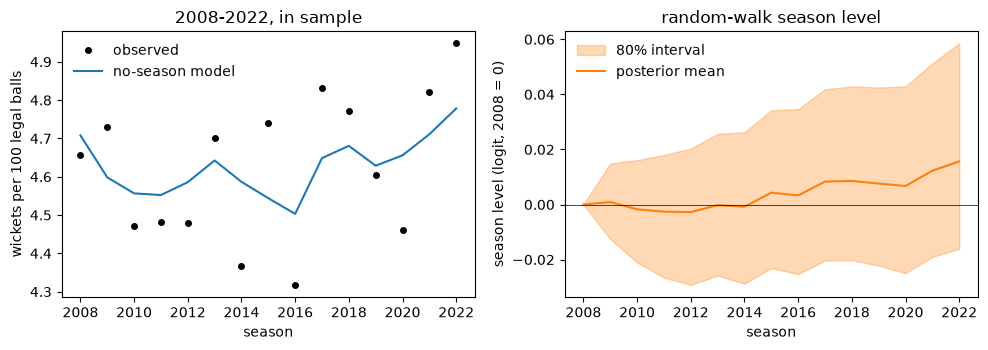

In [7]:
idx22 = H.make_index(tr22)
d0 = H.Draws.from_idata(val_fits["none"])
c0 = season_cells(tr22, idx22)
P0 = expit(d0.alpha[c0.phase_idx.to_numpy()] + d0.bat[c0.bat_idx.to_numpy()]
          + d0.bowl[c0.bowl_idx.to_numpy()])
c0["expected"] = (P0 * c0.n.to_numpy()[:, None]).mean(1)
by_season = c0.groupby("season")[["n", "k", "expected"]].sum()
by_season["observed rate"] = by_season.k / by_season.n
by_season["no-season model"] = by_season.expected / by_season.n
lev = val_fits["random walk"].posterior["level"].stack(s=("chain", "draw"))
by_season["rw level"] = lev.mean("s").to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ax = axes[0]
ax.plot(by_season.index, 100 * by_season["observed rate"], "ko", ms=4, label="observed")
ax.plot(by_season.index, 100 * by_season["no-season model"], "C0-", label="no-season model")
ax.set_xlabel("season")
ax.set_ylabel("wickets per 100 legal balls")
ax.legend(frameon=False)
ax.set_title("2008-2022, in sample")
ax = axes[1]
q = lev.quantile([0.1, 0.9], "s").to_numpy()
ax.fill_between(by_season.index, q[0], q[1], color="C1", alpha=0.3, label="80% interval")
ax.plot(by_season.index, by_season["rw level"], "C1-", label="posterior mean")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("season")
ax.set_ylabel("season level (logit, 2008 = 0)")
ax.set_title("random-walk season level")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "season_drift.png", dpi=150)
by_season.round(5)

## Where the test-season gap sits

The predictions saved by `02_baseline` split by whether the batter and the bowler were seen
in training (2008 to 2023).

In [8]:
gap = base.assign(season=test.season.to_numpy(),
                  batter=np.where(base.batter_id.isin(train.batter_id), "seen", "new"),
                  bowler=np.where(base.bowler_id.isin(train.bowler_id), "seen", "new"))
gap_table = (gap.groupby(["batter", "bowler"])
             .agg(balls=("wicket", "size"), observed=("wicket", "mean"),
                  logistic=("p_logistic", "mean"))
             .reset_index())
gap_table["observed - predicted"] = gap_table.observed - gap_table.logistic
gap_table.to_csv(RESULTS / "test_gap_by_new_player.csv", index=False)
gap_table.round(4)

,batter,bowler,balls,observed,logistic,observed - predicted
0,new,new,512,0.0566,0.0485,0.0081
1,new,seen,3648,0.0630,0.0500,0.0131
2,seen,new,3173,0.0448,0.0459,-0.0011
3,seen,seen,25473,0.0491,0.0487,0.0004


## Test seasons, for the record

**Decision on 2023.** The logistic baseline gets no season term: in cross-validation the
season coefficient was negative in all five folds and the mean log loss was 0.188568 with it
against 0.188557 without. For the hierarchical model, linear and random walk tie on 2023
(log loss 0.195723 and 0.195722 against 0.195743 with no term), and neither difference from
"no term" is distinguishable from zero. I take the linear trend: one parameter, no
divergences (the random walk had one), and its mean prediction for 2023 (4.97%) is the
closest to the observed 4.98%.

Now refit "none" and "linear" on 2008 to 2023 and score 2024 and 2025.

In [9]:
test_rows, tp = [], test[["match_id", "wicket"]].copy()
for trend in ["none", "linear"]:
    idx, idata = fit(train, trend, SEED)
    tp[f"p_{trend}"] = predict(test, idx, idata, trend, SEED)
    test_rows.append({"season term": trend, **diagnostics(idata, trend),
                      **scores(test.wicket, tp[f"p_{trend}"]),
                      "mean predicted": tp[f"p_{trend}"].mean()})
    if trend == "linear":
        print(az.summary(idata, var_names=["beta"]).to_string())
tt = pd.DataFrame(test_rows)
tt["observed"] = test.wicket.mean()
tt.to_csv(RESULTS / "season_test.csv", index=False)
tb = match_bootstrap(tp, ["p_none", "p_linear"], n_boot=1000, seed=SEED)
display(tt.round(6))
difference_interval(tb, "p_linear", "p_none")

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, sigma_bat, sigma_bowl, z_bat, z_bowl]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 252 seconds.


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, sigma_bat, sigma_bowl, z_bat, z_bowl, beta]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 256 seconds.


       mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  r_hat
beta  0.041  0.027  -0.008    0.095        0.0      0.0    5251.0    3443.0    1.0


,season term,divergences,max rhat,min ess bulk,log_loss,brier,mean predicted,observed
0,none,0,1.01,1389,0.197133,0.047575,0.048490,0.050357
1,linear,0,1.01,799,0.197077,0.047571,0.049777,0.050357


,2.5%,median,97.5%
log_loss,-0.000114,-0.000055,0.000007
brier,-0.000011,-0.000004,0.000003


## Conclusion

* **The rise is mostly a change of players.** The raw rate went from 4.3% (2016) to 5.0%
  (2023 to 2025). The model with no season term, using only who batted and who bowled,
  already rises from 4.50% to 4.78% in sample between 2016 and 2022. The random-walk season
  level left over is small: 0.016 on the logit scale by 2022 (80% interval -0.016 to 0.058),
  about 1.5% of the rate, with $\sigma_{rw} = 0.012$.
* **A linear trend fixes the average, not much else.** On the test seasons it moves the mean
  prediction from 4.85% to 4.98% (observed 5.04%). Log loss improves from 0.197133 to
  0.197077, a difference of -0.000055 with a 95% match-bootstrap interval of -0.000114 to
  0.000007, so it is not distinguishable from zero. The trend is 0.041 per decade on the
  logit scale (94% HDI -0.008 to 0.095).
* **The remaining gap is new batters.** Batters first seen in 2024 or 2025 were out on
  6.30% of balls against seen bowlers, where the baseline predicted 5.00% (3,648 balls). For
  batters and bowlers both seen in training, observed and predicted agree (4.91% and 4.87%).
  The model treats a new batter as an average batter, but new batters are mostly lower-order
  players. A batting-position term is the next step (`05_batting_role`).

The linear trend goes into the package model, since it costs nothing and corrects the
average. The logistic baseline stays as it was.